# Fewer Bits, Same Brain: Quantization Demo
**Raaj Banga**

- **The question:** if you shrink a language model, how much dumber does it get?
- **Parts 1–3, how it works:** toy examples that run in seconds.
- **Parts 4–6, does it work:** someone else already compressed Qwen3-4B into six sizes (16-bit down to 1.5-bit).
  - We **don't compress anything here.**
  - We load each size, give it the same tests, and measure what the compression cost.
- **`RUN_MODELS = False`** skips the ~75-minute model run and re-draws the saved results.

## 0 · Setup
- **VS Code (Jupyter extension):** choose the kernel **Quantization Demo (.venv)** in the top-right kernel picker.
- **Terminal:** `jupyter notebook quantization_demo.ipynb` from the activated `.venv`.

In [1]:
# --- Libraries -------------------------------------------------------------
# numpy       : fast math on big lists of numbers (our "weights")
# matplotlib  : charts
# pandas      : tables of results
# gguf        : reads .gguf model files (the format LM Studio / Ollama / llama.cpp use)
# llama_cpp   : actually runs the model (uses the Mac GPU through Apple's "Metal")
import os, re, json, time, math, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT    = Path.cwd()
MODELS  = ROOT / "models"            # downloaded model files live here (git-ignored)
RESULTS = ROOT / "results"           # saved numbers + charts live here (committed)
FIGS    = RESULTS / "figures"
for p in (MODELS, RESULTS, FIGS): p.mkdir(exist_ok=True)

# Flip this to False to skip the slow part and just re-plot the saved results.
RUN_MODELS = False  # True = run all 6 models again (~75 min)

# One consistent look for every chart: light background, one accent colour.
INK, MUTED, ACCENT, BAD = "#16161a", "#6e6e78", "#3b3bf2", "#e5484d"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
})
print(platform.platform(), "| numpy", np.__version__)

macOS-27.2.1-arm64-arm-64bit-Mach-O | numpy 2.5.4


## 1 · Rounding into buckets
- *b* bits = 2^*b* possible values ("buckets").
- Quantizing = snapping each weight to the nearest bucket.

| bits | buckets |
|---|---|
| 16 | 65,536 |
| 8 | 256 |
| 4 | 16 |
| 2 | 4 |

In [2]:
def quantize(x, bits):
    # Symmetric round-to-nearest: buckets are evenly spaced and centred on zero.
    # Returns the "rebuilt" numbers so we can compare them with the originals.
    levels = 2 ** (bits - 1) - 1          # e.g. 4 bits -> integers -7..7
    levels = max(levels, 1)               # 2 bits -> -1, 0, 1  (plus one spare code)
    scale  = np.abs(x).max() / levels     # bucket width
    q      = np.round(x / scale).clip(-levels, levels)   # the small integers we'd store
    return q * scale                      # what the model actually "sees"

# Eight made-up weights (real ones look like this: small, centred on zero)
w = np.array([0.0374, -0.0812, 0.0055, 0.1203, -0.0431, 0.0920, -0.1150, 0.0268])

rows = []
for bits in (8, 4, 2):
    w_hat = quantize(w, bits)
    rows.append({"bits": bits, "buckets": 2**bits,
                 "rebuilt weights": np.round(w_hat, 4).tolist(),
                 "avg error": f"{np.abs(w - w_hat).mean():.4f}"})
print("original:", w.tolist())
pd.DataFrame(rows)

original: [0.0374, -0.0812, 0.0055, 0.1203, -0.0431, 0.092, -0.115, 0.0268]


,bits,buckets,rebuilt weights,avg error
0,8,256,"[0.0369, -0.0815, 0.0057, 0.1203, -0.0436, 0.0...",0.0003
1,4,16,"[0.0344, -0.0859, 0.0, 0.1203, -0.0516, 0.0859...",0.0051
2,2,4,"[0.0, -0.1203, 0.0, 0.1203, -0.0, 0.1203, -0.1...",0.0232


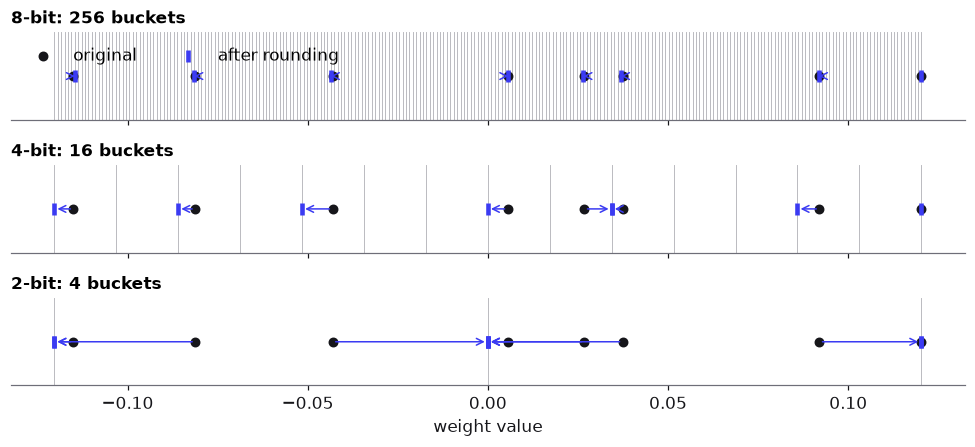

In [3]:
# Picture it: each dot is a weight; vertical lines are the buckets it's allowed to snap to.
fig, axes = plt.subplots(3, 1, figsize=(9, 4.2), sharex=True)
for ax, bits in zip(axes, (8, 4, 2)):
    levels = max(2 ** (bits - 1) - 1, 1)
    scale  = np.abs(w).max() / levels
    for k in range(-levels, levels + 1):
        ax.axvline(k * scale, color=MUTED, lw=0.6, alpha=0.5)
    w_hat = quantize(w, bits)
    ax.scatter(w, np.zeros_like(w), color=INK, s=30, zorder=3, label="original")
    ax.scatter(w_hat, np.zeros_like(w), color=ACCENT, s=60, marker="|", lw=3, zorder=4, label="after rounding")
    for a, b in zip(w, w_hat):
        ax.annotate("", xy=(b, 0), xytext=(a, 0), arrowprops=dict(arrowstyle="->", color=ACCENT, lw=1))
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_title(f"{bits}-bit: {2**bits} buckets", fontsize=11)
axes[0].legend(loc="upper left", frameon=False, ncol=2)
axes[-1].set_xlabel("weight value")
plt.tight_layout(); plt.savefig(FIGS / "01_rounding_buckets.png", bbox_inches="tight"); plt.show()

## 2 · Same idea on a picture
- An image is a grid of numbers, so it can be rounded the same way.
- At 4 bits the picture still looks right.
- That's why image generators handle quantization so well.

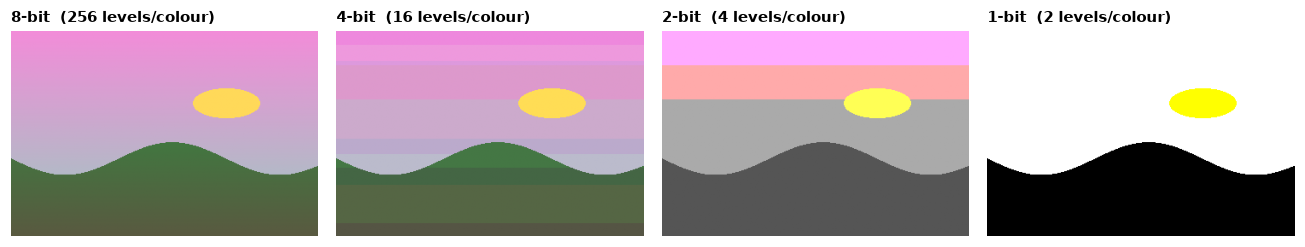

In [4]:
# Build a simple picture from math (no download needed): sky gradient, sun, hills.
H, W = 240, 360
yy, xx = np.mgrid[0:H, 0:W] / np.array([H, W])[:, None, None]
img = np.zeros((H, W, 3))
img[..., 0] = 0.95 - 0.35 * yy          # red channel: warm at top
img[..., 1] = 0.55 + 0.25 * yy          # green
img[..., 2] = 0.85 - 0.10 * yy          # blue
sun = ((xx - 0.7) ** 2 + ((yy - 0.35) * 1.5) ** 2) < 0.012
img[sun] = [1.0, 0.85, 0.35]
hills = yy > 0.62 + 0.08 * np.sin(xx * 9)
img[hills] = np.stack([0.15 + 0.2 * yy, 0.35 + 0.25 * (1 - yy), 0.25 + 0 * yy], -1)[hills]

def posterize(im, bits):
    # Round every brightness value (0..1) to one of 2**bits evenly spaced levels.
    n = 2 ** bits - 1
    return np.round(im * n) / n

fig, axes = plt.subplots(1, 4, figsize=(12, 2.6))
for ax, bits in zip(axes, (8, 4, 2, 1)):
    ax.imshow(posterize(img, bits)); ax.axis("off")
    ax.set_title(f"{bits}-bit  ({2**bits} levels/colour)", fontsize=10)
plt.tight_layout(); plt.savefig(FIGS / "02_image_posterize.png", bbox_inches="tight"); plt.show()

## 3 · One outlier ruins it
- The biggest number sets the bucket width.
- One huge outlier makes the buckets so wide that normal weights all round to 0.
- **Fix:** give every block of 32 weights its own scale.

In [5]:
rng = np.random.default_rng(0)
weights = rng.normal(0, 0.02, 4096)       # 4,096 normal-looking weights
weights_out = weights.copy()
weights_out[123] = 1.0                    # ...plus ONE outlier, ~50x bigger than the rest

def quantize_blocks(x, bits, block=32):
    # Same rounding as before, but each block of `block` numbers gets its own scale.
    out = np.empty_like(x)
    for i in range(0, len(x), block):
        out[i:i+block] = quantize(x[i:i+block], bits)
    return out

def rel_err(x, x_hat):  # error as a % of the typical weight size
    return 100 * np.abs(x - x_hat).mean() / np.abs(x).mean()

table = pd.DataFrame({
    "no outlier, one scale":  [rel_err(weights, quantize(weights, b)) for b in (8, 4, 3)],
    "outlier, one scale":     [rel_err(weights_out, quantize(weights_out, b)) for b in (8, 4, 3)],
    "outlier, block scales":  [rel_err(weights_out, quantize_blocks(weights_out, b)) for b in (8, 4, 3)],
}, index=["8-bit", "4-bit", "3-bit"]).round(1)
print("Average rounding error, as % of a typical weight:")
table

Average rounding error, as % of a typical weight:


,"no outlier, one scale","outlier, one scale","outlier, block scales"
8-bit,1.0,12.1,0.6
4-bit,17.5,98.5,10.4
3-bit,41.1,98.5,23.6


4-bit, one scale   :  99.9% of weights erased to 0
4-bit, block scales:  12.6% of weights erased to 0


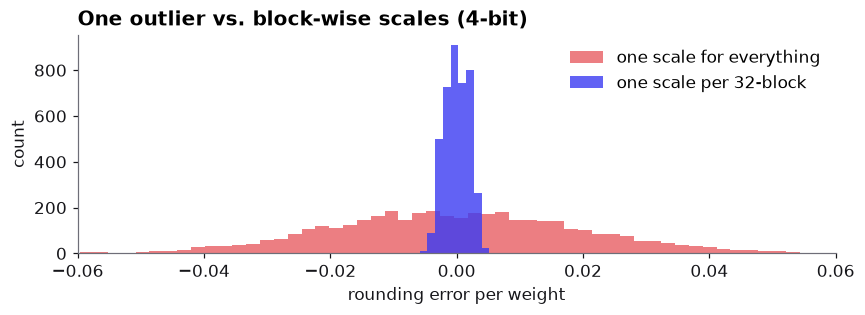

In [6]:
# How many of the 4,096 weights got rounded all the way to ZERO (i.e. erased)?
for name, xh in [("one scale", quantize(weights_out, 4)), ("block scales", quantize_blocks(weights_out, 4))]:
    print(f"4-bit, {name:12s}: {np.mean(xh == 0) * 100:5.1f}% of weights erased to 0")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(weights_out - quantize(weights_out, 4), bins=60, color=BAD, alpha=0.7, label="one scale for everything")
ax.hist(weights_out - quantize_blocks(weights_out, 4), bins=60, color=ACCENT, alpha=0.8, label="one scale per 32-block")
ax.set_xlim(-0.06, 0.06); ax.set_xlabel("rounding error per weight"); ax.set_ylabel("count")
ax.set_title("One outlier vs. block-wise scales (4-bit)"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIGS / "03_outlier_blocks.png", bbox_inches="tight"); plt.show()

## 4 · Get the six pre-compressed files
- **Model:** [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507)
- **Files:** [unsloth GGUF](https://huggingface.co/unsloth/Qwen3-4B-Instruct-2507-GGUF), the same files LM Studio / Ollama use.
- First run downloads ~20 GB into `models/`.

| file | bits per weight |
|---|---|
| F16 | 16 (original) |
| Q8_0 | 8 |
| Q4_K_M | 4 |
| Q3_K_M | 3 |
| Q2_K | 2 |
| IQ1_S | ~1.5 |

In [7]:
from huggingface_hub import hf_hub_download

REPO = "unsloth/Qwen3-4B-Instruct-2507-GGUF"
LEVELS = {                     # label shown on charts : file in the repo
    "F16 (16-bit)":   "Qwen3-4B-Instruct-2507-F16.gguf",
    "Q8_0 (8-bit)":   "Qwen3-4B-Instruct-2507-Q8_0.gguf",
    "Q4_K_M (4-bit)": "Qwen3-4B-Instruct-2507-Q4_K_M.gguf",
    "Q3_K_M (3-bit)": "Qwen3-4B-Instruct-2507-Q3_K_M.gguf",
    "Q2_K (2-bit)":   "Qwen3-4B-Instruct-2507-Q2_K.gguf",
    "IQ1_S (1.5-bit)":"Qwen3-4B-Instruct-2507-UD-IQ1_S.gguf",
}
paths = {}
for label, fname in LEVELS.items():
    if RUN_MODELS or (MODELS / fname).exists():
        paths[label] = Path(hf_hub_download(REPO, fname, local_dir=MODELS))
        print(f"{label:16s} {paths[label].stat().st_size / 1e9:5.2f} GB")

F16 (16-bit)      8.05 GB
Q8_0 (8-bit)      4.28 GB
Q4_K_M (4-bit)    2.50 GB


Q3_K_M (3-bit)    2.08 GB
Q2_K (2-bit)      1.67 GB
IQ1_S (1.5-bit)   1.08 GB


### 4b · How much did rounding change the weights?
- Open the same weight matrix in each file.
- Compare it to the 16-bit original.

blk.18.ffn_up.weight: 24,903,680 weights, mean +0.00001, std 0.02282, max |w| 0.660


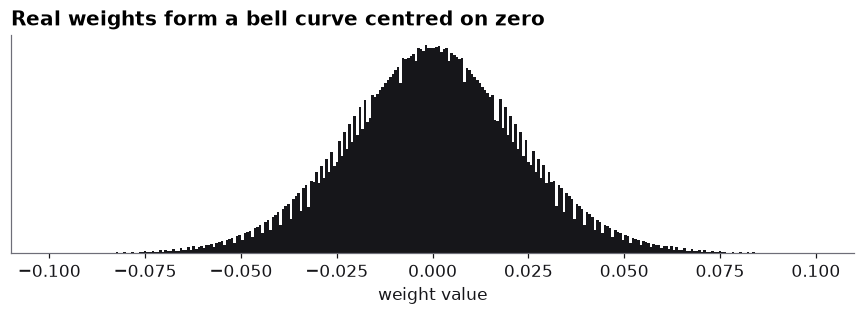

In [8]:
from gguf import GGUFReader
from gguf.quants import dequantize

TENSOR = "blk.18.ffn_up.weight"

def load_tensor(path, name=TENSOR):
    # Open the file without loading all of it into RAM ("memory-mapped"),
    # find the tensor by name, and unpack it into ordinary 32-bit floats.
    r = GGUFReader(path)
    t = next(t for t in r.tensors if t.name == name)
    return dequantize(t.data, t.tensor_type).astype(np.float32), t.tensor_type.name   # 2-D: rows x columns

if paths:
    W16, _ = load_tensor(paths["F16 (16-bit)"])
    W16 = W16.ravel()
    print(f"{TENSOR}: {W16.size:,} weights, mean {W16.mean():+.5f}, std {W16.std():.5f}, max |w| {np.abs(W16).max():.3f}")

    fig, ax = plt.subplots(figsize=(8, 3))
    ax.hist(W16, bins=300, color=INK, range=(-0.1, 0.1))
    ax.set_title("Real weights form a bell curve centred on zero"); ax.set_xlabel("weight value"); ax.set_yticks([])
    plt.tight_layout(); plt.savefig(FIGS / "04_real_weight_hist.png", bbox_inches="tight"); plt.show()

,file,format used for this tensor,avg error (% of avg |w|),weights erased to 0 (%)
0,Q8_0 (8-bit),Q8_0,0.600000,0.8
1,Q4_K_M (4-bit),Q4_K,7.600000,0.0
2,Q3_K_M (3-bit),Q3_K,15.300000,20.8
3,Q2_K (2-bit),Q2_K,28.100000,0.1
4,IQ1_S (1.5-bit),IQ1_S,50.900002,0.0


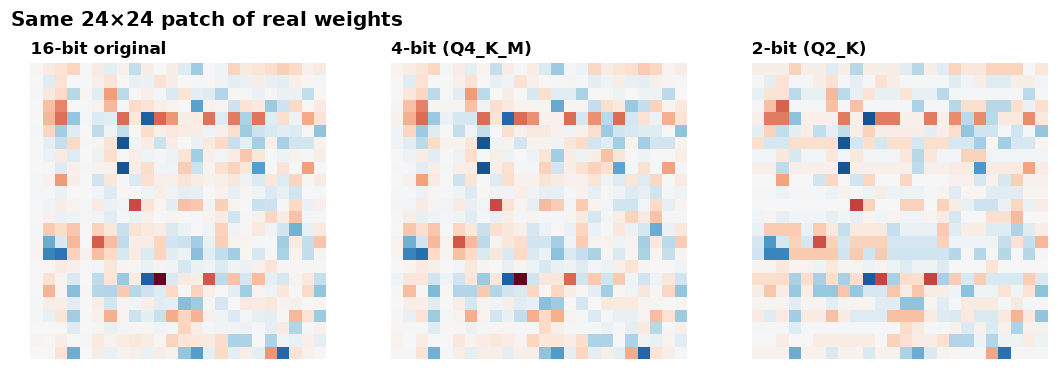

In [9]:
if paths:
    err_rows = []
    for label in ["Q8_0 (8-bit)", "Q4_K_M (4-bit)", "Q3_K_M (3-bit)", "Q2_K (2-bit)", "IQ1_S (1.5-bit)"]:
        if label not in paths: continue
        Wq, qtype = load_tensor(paths[label]); Wq = Wq.ravel()
        err = W16 - Wq                                   # E = W - W_hat : the damage done
        err_rows.append({"file": label, "format used for this tensor": qtype,
                         "avg error (% of avg |w|)": round(100 * np.abs(err).mean() / np.abs(W16).mean(), 1),
                         "weights erased to 0 (%)": round(100 * np.mean((Wq == 0) & (W16 != 0)), 1)})
    weight_err = pd.DataFrame(err_rows); weight_err.to_csv(RESULTS / "weight_error.csv", index=False)
    display(weight_err)

    # Zoom into a 24x24 patch of the matrix: original vs 4-bit vs 2-bit.
    n_cols = 2560   # ffn_up in Qwen3-4B: each row has 2,560 inputs
    patch = lambda v: v.ravel()[: 24 * n_cols].reshape(24, n_cols)[:, :24]
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
    vmax = np.abs(patch(W16)).max()
    for ax, (title, v) in zip(axes, [("16-bit original", W16),
                                     ("4-bit (Q4_K_M)", load_tensor(paths["Q4_K_M (4-bit)"])[0]),
                                     ("2-bit (Q2_K)", load_tensor(paths["Q2_K (2-bit)"])[0])]):
        ax.imshow(patch(v), cmap="RdBu_r", vmin=-vmax, vmax=vmax); ax.set_title(title, fontsize=11); ax.axis("off")
    plt.suptitle("Same 24×24 patch of real weights", x=0.02, ha="left", fontweight="bold")
    plt.tight_layout(); plt.savefig(FIGS / "05_weight_patch.png", bbox_inches="tight"); plt.show()

**Why does 3-bit "erase" more weights than 2-bit?**
- The "erased to 0" column depends on whether a format *has* a bucket at exactly zero.
- **Q8_0 and Q3_K** center their buckets on zero (symmetric), so small weights can land exactly on 0.
- **Q4_K and Q2_K** shift each block's buckets by a per-block minimum (affine), so there's usually no bucket at exactly 0.
- So that column is a quirk of the format. **Average error** is the fair comparison, and it gets steadily worse as bits go down.

### 4c · Not every layer gets the same bits
- "M" = mixed.
- Sensitive layers are kept at higher precision.

In [10]:
from collections import Counter
if paths:
    mix = {}
    for label, p in paths.items():
        counts = Counter(t.tensor_type.name for t in GGUFReader(p).tensors if t.name.endswith(".weight") and t.n_elements > 1e6)
        mix[label] = dict(counts.most_common())
    display(pd.DataFrame(mix).fillna(0).astype(int).T)   # rows: file, columns: storage format, values: number of big weight matrices

,F16,Q8_0,Q4_K,Q6_K,Q3_K,Q5_K,Q2_K,IQ1_S,IQ1_M,IQ2_XXS,IQ3_XXS,IQ3_S,IQ2_S
F16 (16-bit),253,0,0,0,0,0,0,0,0,0,0,0,0
Q8_0 (8-bit),0,253,0,0,0,0,0,0,0,0,0,0,0
Q4_K_M (4-bit),0,0,216,37,0,0,0,0,0,0,0,0,0
Q3_K_M (3-bit),0,0,104,1,144,4,0,0,0,0,0,0,0
Q2_K (2-bit),0,0,36,1,72,0,144,0,0,0,0,0,0
IQ1_S (1.5-bit),0,0,0,0,0,1,28,106,52,51,5,5,5


## 5 · Test every size the same way
- Compression always loses *some* detail.
- These tests measure whether the model *notices*.
- Each skill gets an **easy** test and a **hard** test, so small losses can show up before the cliff.
- `temperature=0` so every run is repeatable.

| test | measures | difficulty |
|---|---|---|
| file size | memory needed | |
| tokens / sec | speed | |
| perplexity, one paragraph | surprise on everyday text | easy |
| perplexity, WikiText-2 | surprise on Wikipedia text, the benchmark papers use | standard |
| 20 math problems (mine) | reasoning | easy |
| 50 GSM8K problems | reasoning | hard |
| 10 short JSON calls (2–3 arguments) | exact formatting | easy |
| 8 long JSON calls (5–6 arguments, lists, nested) | exact formatting | hard |

In [11]:
# ---- Test set 1: math word problems (question, correct answer) -------------
MATH = [
    ("A bakery makes 12 trays of 18 cookies and sells 150 cookies. How many cookies are left?", 66),
    ("Sam has $85. He buys 3 books at $12 each and a bag for $27. How many dollars does he have left?", 22),
    ("A train travels at 60 mph for 2.5 hours, then at 40 mph for 1.5 hours. How many miles does it travel in total?", 210),
    ("A class has 32 students. 3/8 walk to school, 1/4 take the bus, and the rest come by car. How many come by car?", 12),
    ("Pens are sold only in packs of 6 for $4 a pack. You need at least 45 pens. How many dollars do you spend?", 32),
    ("A garden is 14 m by 9 m. Fencing around the whole edge costs $3 per metre. How many dollars does the fence cost?", 138),
    ("Maria reads 25 pages a day. Her book has 340 pages. After 9 days, how many pages are left?", 115),
    ("A 500 L tank drains 35 L per hour for 6 hours, then 80 L is added. How many litres are in the tank?", 370),
    ("A $75 shirt is 20% off, and then you use a $5 coupon. What is the final price in dollars?", 55),
    ("4 friends split a $96 bill plus a 25% tip equally. How many dollars does each person pay?", 30),
    ("Jake is 3 times as old as his sister, who is 7. What will the sum of their ages be in 5 years?", 38),
    ("A recipe needs 3 eggs for every 2 cakes. How many eggs are needed for 14 cakes?", 21),
    ("A factory makes 245 widgets a day, 5 days a week. How many widgets does it make in 4 weeks?", 4900),
    ("Tom has $40 and saves $15 every week. After how many weeks will he have exactly $205?", 11),
    ("A rectangle has an area of 96 and a width of 8. What is its perimeter?", 40),
    ("There are 7 boxes of 24 apples. 19 apples are rotten and thrown away. The rest are packed into bags of 5. How many full bags are there?", 29),
    ("A bus has 38 passengers. At the first stop 12 get off and 7 get on. At the second stop 9 get off and 15 get on. How many passengers are on the bus now?", 39),
    ("Lena earns $18 an hour and works 7 hours a day for 5 days. She spends $230. How many dollars does she have left?", 400),
    ("A car uses 8 litres of fuel per 100 km. How many litres does it need for 350 km?", 28),
    ("There are 3 shelves with 27 books each. One third of all the books are donated. How many books remain?", 54),
]

# ---- Test set 2: JSON function calls (request, expected call) ---------------
JSON_TASKS = [
    ("What's the weather in Paris? Use celsius.", "get_weather(city: string, unit: 'celsius'|'fahrenheit')",
     {"name": "get_weather", "arguments": {"city": "Paris", "unit": "celsius"}}),
    ("Tell me the weather in Tokyo in fahrenheit.", "get_weather(city: string, unit: 'celsius'|'fahrenheit')",
     {"name": "get_weather", "arguments": {"city": "Tokyo", "unit": "fahrenheit"}}),
    ("Set a 15 minute timer called pasta.", "set_timer(minutes: integer, label: string)",
     {"name": "set_timer", "arguments": {"minutes": 15, "label": "pasta"}}),
    ("Email alex@example.com with the subject 'Meeting moved'.", "send_email(to: string, subject: string)",
     {"name": "send_email", "arguments": {"to": "alex@example.com", "subject": "Meeting moved"}}),
    ("Convert 250 US dollars to euros.", "convert_currency(amount: number, from: 3-letter code, to: 3-letter code)",
     {"name": "convert_currency", "arguments": {"amount": 250, "from": "USD", "to": "EUR"}}),
    ("Book a table at Luigi's for 4 people at 19:30.", "book_table(restaurant: string, people: integer, time: 'HH:MM')",
     {"name": "book_table", "arguments": {"restaurant": "Luigi's", "people": 4, "time": "19:30"}}),
    ("Add 'buy milk' to my todo list, high priority.", "add_todo(task: string, priority: 'low'|'medium'|'high')",
     {"name": "add_todo", "arguments": {"task": "buy milk", "priority": "high"}}),
    ("Find flights from CHI to NYC on 2026-12-03.", "search_flights(origin: string, destination: string, date: 'YYYY-MM-DD')",
     {"name": "search_flights", "arguments": {"origin": "CHI", "destination": "NYC", "date": "2026-12-03"}}),
    ("Play Daft Punk on shuffle.", "play_music(artist: string, shuffle: boolean)",
     {"name": "play_music", "arguments": {"artist": "Daft Punk", "shuffle": True}}),
    ("What's an 18 percent tip on an $84.50 bill?", "calc_tip(bill: number, percent: number)",
     {"name": "calc_tip", "arguments": {"bill": 84.5, "percent": 18}}),
]

# ---- Text for perplexity (original paragraph, plain everyday English) --------
PPL_TEXT = (
    "The library on the corner of Fifth Street opens at nine in the morning and closes at six in the evening. "
    "On weekdays it is usually quiet, except for a group of retirees who meet every Tuesday to talk about the "
    "books they have been reading. Last month they read a long novel about a family of farmers who moved west "
    "during a drought, and the discussion went on for nearly two hours. The librarian, who has worked there for "
    "more than twenty years, says that the most popular section is still the one with cookbooks, even though "
    "most people now look up recipes on their phones. Children visit in the afternoon after school, and on "
    "Saturdays there is a reading hour where volunteers read picture books out loud. The building itself is "
    "more than a hundred years old, and the town recently voted to repair the roof and replace the old windows "
    "so that the reading room stays warm in the winter."
)
SHOWCASE = [
    "In two sentences, explain why the sky is blue.",
    "Write a Python function `is_prime(n)` that returns True if n is prime. Code only.",
]
print(len(MATH), "math problems |", len(JSON_TASKS), "JSON tasks")

20 math problems | 10 JSON tasks


In [12]:
# ---- Hard test sets ---------------------------------------------------------
from huggingface_hub import hf_hub_download

# GSM8K (Cobbe et al., 2021): grade-school math word problems, the standard reasoning benchmark.
# We take a fixed random sample of 50 from the 1,319 test problems (same 50 every run).
gsm_path = hf_hub_download("openai/gsm8k", "main/test-00000-of-00001.parquet", repo_type="dataset", local_dir=MODELS / "data")
gsm = pd.read_parquet(gsm_path).sample(50, random_state=0)
GSM8K = [(q, float(a.split("####")[-1].strip().replace(",", ""))) for q, a in zip(gsm.question, gsm.answer)]

# WikiText-2 (Merity et al., 2017): Wikipedia articles; the text every quantization paper reports perplexity on.
# We use the first 4,096 tokens of the test set, in 8 windows of 512 tokens.
wiki_path = hf_hub_download("Salesforce/wikitext", "wikitext-2-raw-v1/test-00000-of-00001.parquet", repo_type="dataset", local_dir=MODELS / "data")
WIKI_TEXT = "".join(pd.read_parquet(wiki_path).text)

# Long JSON calls: 5–6 arguments each, including lists, true/false values and one nested object.
JSON_HARD = [
    ("Put 'Design review' on my calendar for March 4th 2027 at 2:30 PM for 45 minutes with sam@example.com and lee@example.com, and remind me.",
     "create_event(title: string, date: 'YYYY-MM-DD', start: 'HH:MM' 24-hour, duration_minutes: integer, attendees: list of emails, remind: boolean)",
     {"name": "create_event", "arguments": {"title": "Design review", "date": "2027-03-04", "start": "14:30", "duration_minutes": 45,
                                            "attendees": ["sam@example.com", "lee@example.com"], "remind": True}}),
    ("Book 2 business-class seats from Chicago O'Hare to New York JFK on 2027-01-15, refundable please.",
     "book_flight(origin: 3-letter airport code, destination: 3-letter airport code, date: 'YYYY-MM-DD', passengers: integer, cabin: 'economy'|'business'|'first', refundable: boolean)",
     {"name": "book_flight", "arguments": {"origin": "ORD", "destination": "JFK", "date": "2027-01-15", "passengers": 2, "cabin": "business", "refundable": True}}),
    ("Two large pizzas with mushrooms and olives, delivered to 12 Oak St.",
     "order_pizza(size: 'small'|'medium'|'large', toppings: list of strings, quantity: integer, delivery: boolean, address: string)",
     {"name": "order_pizza", "arguments": {"size": "large", "toppings": ["mushrooms", "olives"], "quantity": 2, "delivery": True, "address": "12 Oak St"}}),
    ("Set the bedroom to 21.5 degrees on heat from 22:00 to 06:30, with eco mode off.",
     "set_thermostat(room: string, temperature_c: number, mode: 'heat'|'cool'|'auto', schedule: {start: 'HH:MM', end: 'HH:MM'}, eco: boolean)",
     {"name": "set_thermostat", "arguments": {"room": "bedroom", "temperature_c": 21.5, "mode": "heat", "schedule": {"start": "22:00", "end": "06:30"}, "eco": False}}),
    ("Find wireless headphones under $120 rated at least 4.5 stars, only ones in stock, cheapest first.",
     "search_products(query: string, max_price: number, min_rating: number, in_stock: boolean, sort: 'price_asc'|'price_desc'|'rating')",
     {"name": "search_products", "arguments": {"query": "wireless headphones", "max_price": 120, "min_rating": 4.5, "in_stock": True, "sort": "price_asc"}}),
    ("File an urgent ticket called 'Login page crashes', labelled bug and frontend, assigned to maria, due 2027-02-01, estimated at 3 hours.",
     "create_ticket(title: string, priority: 'low'|'medium'|'high'|'urgent', labels: list of strings, assignee: string, due: 'YYYY-MM-DD', estimate_hours: number)",
     {"name": "create_ticket", "arguments": {"title": "Login page crashes", "priority": "urgent", "labels": ["bug", "frontend"], "assignee": "maria", "due": "2027-02-01", "estimate_hours": 3}}),
    ("Text Alex and Jordan 'Running 10 min late' by SMS. Not urgent, no attachments.",
     "send_message(platform: 'slack'|'email'|'sms', to: list of names, text: string, urgent: boolean, attachments: list of file names)",
     {"name": "send_message", "arguments": {"platform": "sms", "to": ["Alex", "Jordan"], "text": "Running 10 min late", "urgent": False, "attachments": []}}),
    ("Resize photo.png to 800 by 600 as a webp at quality 85, and don't keep the aspect ratio.",
     "resize_image(file: string, width: integer, height: integer, format: 'png'|'jpg'|'webp', keep_aspect: boolean, quality: integer 1-100)",
     {"name": "resize_image", "arguments": {"file": "photo.png", "width": 800, "height": 600, "format": "webp", "keep_aspect": False, "quality": 85}}),
]
print(len(GSM8K), "GSM8K problems |", len(JSON_HARD), "long JSON tasks |", f"{len(WIKI_TEXT):,} characters of WikiText-2")

50 GSM8K problems | 8 long JSON tasks | 1,285,622 characters of WikiText-2


In [13]:
# ---- Graders: turn the model's text reply into right / wrong ----------------
def grade_math(reply, answer):
    # Look for "Final answer: <number>"; otherwise take the last number in the reply.
    m = re.search(r"final answer\s*[:=]?\s*\$?\s*(-?[\d,]*\.?\d+)", reply, re.I)
    nums = [m.group(1)] if m else re.findall(r"-?[\d,]*\.?\d+", reply)
    if not nums: return False
    try:    return abs(float(nums[-1].replace(",", "")) - answer) < 1e-6
    except: return False

def norm(v):  # compare loosely: case-insensitive strings, numbers as floats, lists in any order
    if isinstance(v, bool): return v
    if isinstance(v, (int, float)): return float(v)
    if isinstance(v, str): return v.strip().rstrip(".").lower()
    if isinstance(v, list): return sorted(json.dumps(norm(x)) for x in v)
    if isinstance(v, dict): return {k: norm(x) for k, x in v.items()}
    return v

def grade_json(reply, expected):
    # Returns (is_valid_json, is_exactly_right_call)
    txt = re.sub(r"^```(?:json)?|```$", "", reply.strip(), flags=re.M).strip()
    try:    obj = json.loads(txt)
    except Exception: return False, False
    ok = (isinstance(obj, dict) and norm(obj.get("name")) == norm(expected["name"])
          and isinstance(obj.get("arguments"), dict)
          and set(obj["arguments"]) == set(expected["arguments"])
          and norm(obj["arguments"]) == norm(expected["arguments"]))
    return True, ok

assert grade_math("so 3 x 22... Final answer: 66", 66) and not grade_math("Final answer: 65", 66)
assert grade_json('{"name":"set_timer","arguments":{"minutes":15,"label":"Pasta"}}', JSON_TASKS[2][2]) == (True, True)
print("graders OK")

graders OK


In [14]:
def run_level(label, path):
    # Run every test on one compression level and return a dict of results.
    from llama_cpp import Llama
    t0 = time.time()
    llm = Llama(model_path=str(path), n_ctx=2048, n_gpu_layers=-1,  # -1 = put every layer on the GPU
                logits_all=True, verbose=False, seed=0)
    load_s = time.time() - t0

    def chat(messages, max_tokens=320):
        out = llm.create_chat_completion(messages=messages, temperature=0.0, max_tokens=max_tokens)
        return out["choices"][0]["message"]["content"], out["usage"]["completion_tokens"]

    # Speed: time a fixed 128-token generation (ignore_eos would be ideal; we just count tokens produced)
    t0 = time.time()
    _, n_tok = chat([{"role": "user", "content": "Write a short story about a lighthouse keeper."}], max_tokens=128)
    tok_s = n_tok / (time.time() - t0)

    # Perplexity: feed the paragraph in, read the model's predicted probability for each next word.
    toks = llm.tokenize(PPL_TEXT.encode())
    llm.reset(); llm.eval(toks)
    logits = np.array(llm.scores[: len(toks)], dtype=np.float64)
    logp = logits - logits.max(1, keepdims=True)
    logp = logp - np.log(np.exp(logp).sum(1, keepdims=True))
    nll = -logp[np.arange(len(toks) - 1), toks[1:]]
    ppl = float(np.exp(nll.mean()))

    # WikiText-2 perplexity: same idea on 8 windows of 512 tokens of Wikipedia text.
    wtoks = llm.tokenize(WIKI_TEXT.encode())[: 8 * 512]
    nlls = []
    for i in range(0, len(wtoks), 512):
        w = wtoks[i:i + 512]
        llm.reset(); llm.eval(w)
        lg = np.array(llm.scores[: len(w)], dtype=np.float64)
        lp = lg - lg.max(1, keepdims=True); lp = lp - np.log(np.exp(lp).sum(1, keepdims=True))
        nlls.append(-lp[np.arange(len(w) - 1), w[1:]])
    wiki_ppl = float(np.exp(np.concatenate(nlls).mean()))

    # Math
    math_log = []
    for q, a in MATH:
        reply, _ = chat([{"role": "user", "content": q + "\nThink step by step briefly, then end with 'Final answer: <number>'."}])
        math_log.append({"q": q, "answer": a, "reply": reply, "correct": grade_math(reply, a)})

    # GSM8K (hard math): longer problems, so allow a longer answer
    gsm_log = []
    for q, a in GSM8K:
        reply, _ = chat([{"role": "user", "content": q + "\nThink step by step briefly, then end with 'Final answer: <number>'."}], max_tokens=512)
        gsm_log.append({"q": q, "answer": a, "reply": reply, "correct": grade_math(reply, a)})

    # JSON tool calls
    json_log = []
    for req, sig, exp in JSON_TASKS:
        sys_msg = ("You are a function-calling assistant. Reply with ONLY a JSON object of the form "
                   '{"name": <function name>, "arguments": {...}} and nothing else.')
        reply, _ = chat([{"role": "system", "content": sys_msg},
                         {"role": "user", "content": f"Available function: {sig}\nRequest: {req}"}], max_tokens=120)
        valid, right = grade_json(reply, exp)
        json_log.append({"request": req, "reply": reply, "valid_json": valid, "correct": right})

    # Long JSON tool calls (hard)
    json_hard_log = []
    for req, sig, exp in JSON_HARD:
        reply, _ = chat([{"role": "system", "content": sys_msg},
                         {"role": "user", "content": f"Available function: {sig}\nRequest: {req}"}], max_tokens=200)
        valid, right = grade_json(reply, exp)
        json_hard_log.append({"request": req, "reply": reply, "valid_json": valid, "correct": right})

    showcase = {p: chat([{"role": "user", "content": p}], max_tokens=160)[0] for p in SHOWCASE}
    del llm
    return {"level": label, "file_gb": round(path.stat().st_size / 1e9, 2),
            "bits_per_weight": round(path.stat().st_size * 8 / 4.02e9, 2),   # Qwen3-4B has ~4.02B weights
            "load_s": round(load_s, 1), "tokens_per_s": round(tok_s, 1), "perplexity": round(ppl, 2), "wikitext_ppl": round(wiki_ppl, 2),
            "math_acc": np.mean([m["correct"] for m in math_log]),
            "gsm8k_acc": np.mean([m["correct"] for m in gsm_log]),
            "json_valid": np.mean([j["valid_json"] for j in json_log]),
            "json_correct": np.mean([j["correct"] for j in json_log]),
            "json_hard_valid": np.mean([j["valid_json"] for j in json_hard_log]),
            "json_hard_correct": np.mean([j["correct"] for j in json_hard_log]),
           }, {"math": math_log, "gsm8k": gsm_log, "json": json_log, "json_hard": json_hard_log, "showcase": showcase}

In [15]:
if RUN_MODELS:
    summary, transcripts = [], {}
    for label, path in paths.items():
        t0 = time.time()
        row, logs = run_level(label, path)
        summary.append(row); transcripts[label] = logs
        print(f"{label:16s} done in {time.time()-t0:5.0f}s | {row}")
    pd.DataFrame(summary).to_csv(RESULTS / "results.csv", index=False)
    (RESULTS / "transcripts.json").write_text(json.dumps(transcripts, indent=1))

results = pd.read_csv(RESULTS / "results.csv")
transcripts = json.loads((RESULTS / "transcripts.json").read_text())
results

F16 (16-bit)     done in   470s | {'level': 'F16 (16-bit)', 'file_gb': 8.05, 'bits_per_weight': 16.02, 'load_s': 3.8, 'tokens_per_s': 25.4, 'perplexity': 10.2, 'wikitext_ppl': 14.12, 'math_acc': np.float64(1.0), 'gsm8k_acc': np.float64(0.92), 'json_valid': np.float64(1.0), 'json_correct': np.float64(1.0), 'json_hard_valid': np.float64(1.0), 'json_hard_correct': np.float64(1.0)}


Q8_0 (8-bit)     done in   254s | {'level': 'Q8_0 (8-bit)', 'file_gb': 4.28, 'bits_per_weight': 8.52, 'load_s': 2.0, 'tokens_per_s': 47.8, 'perplexity': 10.19, 'wikitext_ppl': 14.11, 'math_acc': np.float64(1.0), 'gsm8k_acc': np.float64(0.92), 'json_valid': np.float64(1.0), 'json_correct': np.float64(1.0), 'json_hard_valid': np.float64(1.0), 'json_hard_correct': np.float64(1.0)}


Q4_K_M (4-bit)   done in   215s | {'level': 'Q4_K_M (4-bit)', 'file_gb': 2.5, 'bits_per_weight': 4.97, 'load_s': 1.2, 'tokens_per_s': 57.8, 'perplexity': 10.24, 'wikitext_ppl': 14.33, 'math_acc': np.float64(1.0), 'gsm8k_acc': np.float64(0.9), 'json_valid': np.float64(1.0), 'json_correct': np.float64(1.0), 'json_hard_valid': np.float64(1.0), 'json_hard_correct': np.float64(1.0)}


Q3_K_M (3-bit)   done in   289s | {'level': 'Q3_K_M (3-bit)', 'file_gb': 2.08, 'bits_per_weight': 4.13, 'load_s': 1.1, 'tokens_per_s': 40.9, 'perplexity': 11.15, 'wikitext_ppl': 14.93, 'math_acc': np.float64(1.0), 'gsm8k_acc': np.float64(0.88), 'json_valid': np.float64(1.0), 'json_correct': np.float64(1.0), 'json_hard_valid': np.float64(1.0), 'json_hard_correct': np.float64(1.0)}


Q2_K (2-bit)     done in   293s | {'level': 'Q2_K (2-bit)', 'file_gb': 1.67, 'bits_per_weight': 3.32, 'load_s': 0.8, 'tokens_per_s': 56.1, 'perplexity': 11.79, 'wikitext_ppl': 19.06, 'math_acc': np.float64(1.0), 'gsm8k_acc': np.float64(0.9), 'json_valid': np.float64(1.0), 'json_correct': np.float64(1.0), 'json_hard_valid': np.float64(1.0), 'json_hard_correct': np.float64(0.75)}


IQ1_S (1.5-bit)  done in   653s | {'level': 'IQ1_S (1.5-bit)', 'file_gb': 1.08, 'bits_per_weight': 2.16, 'load_s': 0.6, 'tokens_per_s': 54.3, 'perplexity': 53.23, 'wikitext_ppl': 88.48, 'math_acc': np.float64(0.0), 'gsm8k_acc': np.float64(0.0), 'json_valid': np.float64(0.0), 'json_correct': np.float64(0.0), 'json_hard_valid': np.float64(0.0), 'json_hard_correct': np.float64(0.0)}


,level,file_gb,bits_per_weight,load_s,tokens_per_s,perplexity,wikitext_ppl,math_acc,gsm8k_acc,json_valid,json_correct,json_hard_valid,json_hard_correct
0,F16 (16-bit),8.05,16.02,3.8,25.4,10.20,14.12,1.0,0.92,1.0,1.0,1.0,1.00
1,Q8_0 (8-bit),4.28,8.52,2.0,47.8,10.19,14.11,1.0,0.92,1.0,1.0,1.0,1.00
2,Q4_K_M (4-bit),2.50,4.97,1.2,57.8,10.24,14.33,1.0,0.90,1.0,1.0,1.0,1.00
3,Q3_K_M (3-bit),2.08,4.13,1.1,40.9,11.15,14.93,1.0,0.88,1.0,1.0,1.0,1.00
4,Q2_K (2-bit),1.67,3.32,0.8,56.1,11.79,19.06,1.0,0.90,1.0,1.0,1.0,0.75
5,IQ1_S (1.5-bit),1.08,2.16,0.6,54.3,53.23,88.48,0.0,0.00,0.0,0.0,0.0,0.00


## 6 · Results

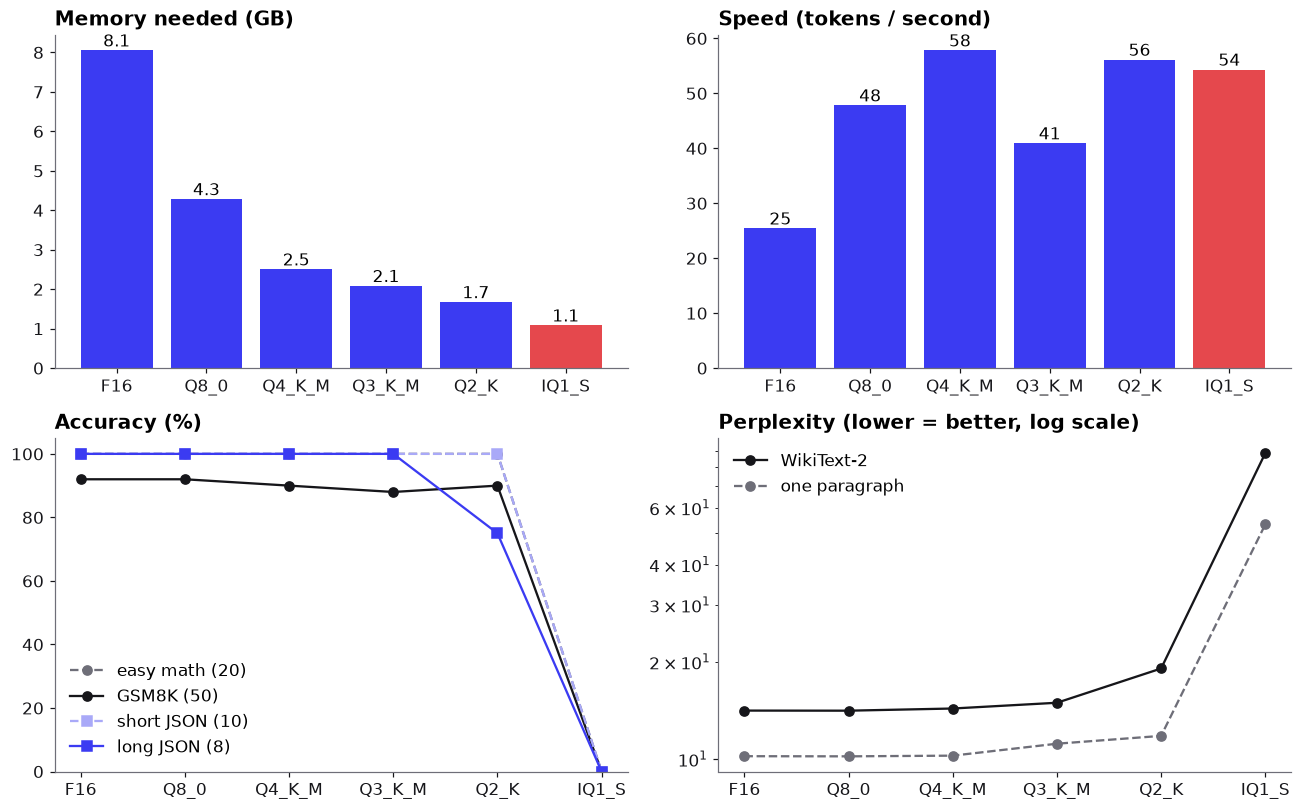

In [16]:
r = results.copy()
short = [l.split(" ")[0] for l in r.level]
colors = [BAD if p > 2 * r.wikitext_ppl[0] else ACCENT for p in r.wikitext_ppl]

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
ax = axes[0, 0]; ax.bar(short, r.file_gb, color=colors)
ax.set_title("Memory needed (GB)"); [ax.text(i, v, f"{v:.1f}", ha="center", va="bottom") for i, v in enumerate(r.file_gb)]
ax = axes[0, 1]; ax.bar(short, r.tokens_per_s, color=colors)
ax.set_title("Speed (tokens / second)"); [ax.text(i, v, f"{v:.0f}", ha="center", va="bottom") for i, v in enumerate(r.tokens_per_s)]
ax = axes[1, 0]
ax.plot(short, r.math_acc * 100, "o--", color=MUTED, label="easy math (20)")
ax.plot(short, r.gsm8k_acc * 100, "o-", color=INK, label="GSM8K (50)")
ax.plot(short, r.json_correct * 100, "s--", color="#a9a9f8", label="short JSON (10)")
ax.plot(short, r.json_hard_correct * 100, "s-", color=ACCENT, label="long JSON (8)")
ax.set_ylim(0, 105); ax.set_title("Accuracy (%)"); ax.legend(frameon=False)
ax = axes[1, 1]; ax.plot(short, r.wikitext_ppl, "o-", color=INK, label="WikiText-2")
ax.plot(short, r.perplexity, "o--", color=MUTED, label="one paragraph"); ax.set_yscale("log"); ax.legend(frameon=False)
ax.set_title("Perplexity (lower = better, log scale)")
plt.tight_layout(); plt.savefig(FIGS / "06_dashboard.png", bbox_inches="tight"); plt.show()

In [17]:
# Side-by-side: the same question at every level. Where does it start going wrong?
for p in SHOWCASE[:1]:
    print("PROMPT:", p, "\n")
    for label, logs in transcripts.items():
        print(f"--- {label}\n{logs['showcase'][p].strip()[:400]}\n")

PROMPT: In two sentences, explain why the sky is blue. 

--- F16 (16-bit)
The sky appears blue because molecules in the atmosphere scatter blue light more than other colors due to its shorter wavelength. This scattered blue light reaches our eyes from all directions, making the sky appear blue during the day.

--- Q8_0 (8-bit)
The sky appears blue because molecules in the atmosphere scatter blue light more than other colors due to its shorter wavelength. This scattered blue light reaches our eyes from all directions, making the sky appear blue during the day.

--- Q4_K_M (4-bit)
The sky appears blue because molecules in the atmosphere scatter blue light more than other colors due to its shorter wavelength. This scattered blue light reaches our eyes from all directions, making the sky appear blue during the day.

--- Q3_K_M (3-bit)
The sky appears blue because molecules in the atmosphere scatter blue light more strongly than other colors due to its shorter wavelength. This scattered blu

In [18]:
# The first JSON request, at every level — watch the format fall apart.
for label, logs in transcripts.items():
    j = logs["json"][0]
    print(f"{label:16s} valid={j['valid_json']!s:5} right={j['correct']!s:5} | {j['reply'].strip()[:110]!r}")

F16 (16-bit)     valid=True  right=True  | '{"name": "get_weather", "arguments": {"city": "Paris", "unit": "celsius"}}'
Q8_0 (8-bit)     valid=True  right=True  | '{"name": "get_weather", "arguments": {"city": "Paris", "unit": "celsius"}}'
Q4_K_M (4-bit)   valid=True  right=True  | '{"name": "get_weather", "arguments": {"city": "Paris", "unit": "celsius"}}'
Q3_K_M (3-bit)   valid=True  right=True  | '{"name": "get_weather", "arguments": {"city": "Paris", "unit": "celsius"}}'
Q2_K (2-bit)     valid=True  right=True  | '{"name": "get_weather", "arguments": {"city": "Paris", "unit": "celsius"}}'
IQ1_S (1.5-bit)  valid=False right=False | 'C, 20000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000'


### What this shows
- **Easy tests: flat, then a cliff.**
  - 16-bit down to 2-bit: 100% on easy math and short JSON. ~1.5-bit: 0% and gibberish.
- **Hard tests: small slips before the cliff.**
  - Long JSON: 100% down to 3-bit, then **75% at 2-bit** (6 of 8).
    - Both misses were *valid* JSON with wrong content: Chicago O'Hare became `"CHI"` instead of `"ORD"`, and a product search dropped its `query`. Silent failures.
  - WikiText-2 perplexity: 14.1 → 14.3 (4-bit) → 14.9 (3-bit) → **19.1 (2-bit)** → 88.5 (1.5-bit).
  - GSM8K: 92% → 90% → 88% → 90% → 0%. Differences above 1.5-bit are 1–2 problems out of 50, so treat them as noise.
- **4-bit is the sweet spot:** 69% smaller, ~2.3× faster, no measurable task loss, perplexity +0.2.

### Limitations
- **Small test sets.** 50 GSM8K problems and 8 long JSON calls can show a real drop (like 2-bit JSON) but not a 1–2% one.
- **WikiText-2 sample.** 8 windows × 512 tokens, not the full test set, so compare levels with each other, not with published numbers.
- **One model.** Larger models generally tolerate low bits better than a 4B one.
- **Mac speeds.** Speed varies run to run (e.g., 3-bit came out slower than 4-bit); the pattern holds on NVIDIA GPUs, the exact numbers don't.
- **Possible fix for JSON:** grammar-constrained decoding forces valid format, but not correct values, and the 2-bit misses were already valid.


## 7 · Live demo (~20 s)
- Asks the 4-bit and 1.5-bit models the same question.
- **Runs on its own:** no need to run the cells above first. It finds the two model files in `models/` (or downloads them, ~3.6 GB, if missing).
- Change `QUESTION` to anything.


In [ ]:
# Self-contained: works right after opening the notebook, without running anything above.
import time
from pathlib import Path
from huggingface_hub import hf_hub_download
from llama_cpp import Llama

# QUESTION = "If I have 170 apples and I have 4 friends, how many apples does each friend get and how many are left over? Answer with just the numbers."   # <- change me live
QUESTION = "What is 100 - 73? Answer with just the numbers."

MODEL_DIR = Path.cwd() / "models"                  # same folder the earlier cells use
DEMO = {                                           # label : file in unsloth/Qwen3-4B-Instruct-2507-GGUF
    "Q4_K_M (4-bit)":  "Qwen3-4B-Instruct-2507-Q4_K_M.gguf",
    "IQ1_S (1.5-bit)": "Qwen3-4B-Instruct-2507-UD-IQ1_S.gguf",
}

for label, fname in DEMO.items():
    path = MODEL_DIR / fname
    if not path.exists():                          # only downloads if the file isn't there yet
        path = Path(hf_hub_download("unsloth/Qwen3-4B-Instruct-2507-GGUF", fname, local_dir=MODEL_DIR))
    llm = Llama(model_path=str(path), n_ctx=1024, n_gpu_layers=-1, verbose=False)
    t0 = time.time()
    out = llm.create_chat_completion([{"role": "user", "content": QUESTION}], temperature=0, max_tokens=120)
    print(f"{label}  ({time.time()-t0:.1f}s)\n  {out['choices'][0]['message']['content'].strip()}\n")
    del llm                                        # free the memory before loading the next model
